<a href="https://colab.research.google.com/github/manaskesarla/community-project-sem-3/blob/main/communityprojecsem3.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Hepatitis C Screening from a Liver Panel
**BCP308 Community Project, Team A-9** | SDG 3, Target 3.3

Goal: classify blood-donor records (UCI HCV Data, id 571) into **Donor / Hepatitis / Fibrosis / Cirrhosis** from ten standard liver-panel values (plus age and sex), and evaluate the model with **recall and precision**, not accuracy. Fewer than 1 in 8 records is positive, so a model that always says "Donor" scores 87.7% accuracy and catches nothing.

**Pipeline:** load, clean, EDA, leakage-safe preprocessing, 7 baseline models (class weights vs SMOTE) with repeated stratified CV, nested-CV tuning, out-of-fold evaluation, screening threshold analysis, explainability, error analysis, demo function.

**Design decisions**
- The 7 "suspect blood donor" records are unconfirmed, so they are excluded from the primary task (608 records remain).
- Imputation, log-transform, scaling and SMOTE all run *inside* the CV folds, so nothing leaks from test folds.
- The column the dataset calls `CGT` is GGT (gamma-glutamyl transferase), and it is renamed here.
- This is a triage aid that flags who should get a confirmatory HCV test. It is not a diagnostic tool.

In [1]:
!pip -q install ucimlrepo imbalanced-learn shap
import numpy as np, pandas as pd, warnings
warnings.filterwarnings("ignore")
SEED = 42
np.random.seed(SEED)

from ucimlrepo import fetch_ucirepo
hcv = fetch_ucirepo(id=571)
X_raw = hcv.data.features
y_raw = hcv.data.targets
print(X_raw.shape, y_raw.shape)
print(X_raw.dtypes)
print(y_raw.iloc[:, 0].value_counts())
print(X_raw.isna().sum()[X_raw.isna().sum() > 0])
X_raw.head()

(615, 12) (615, 1)
Age       int64
Sex      object
ALB     float64
ALP     float64
AST     float64
BIL     float64
CHE     float64
CHOL    float64
CREA    float64
CGT     float64
PROT    float64
ALT     float64
dtype: object
Category
0=Blood Donor             533
3=Cirrhosis                30
1=Hepatitis                24
2=Fibrosis                 21
0s=suspect Blood Donor      7
Name: count, dtype: int64
ALB      1
ALP     18
CHOL    10
PROT     1
ALT      1
dtype: int64


,Age,Sex,ALB,ALP,AST,BIL,CHE,CHOL,CREA,CGT,PROT,ALT
0,32,m,38.5,52.5,22.1,7.5,6.93,3.23,106.0,12.1,69.0,7.7
1,32,m,38.5,70.3,24.7,3.9,11.17,4.80,74.0,15.6,76.5,18.0
2,32,m,46.9,74.7,52.6,6.1,8.84,5.20,86.0,33.2,79.3,36.2
3,32,m,43.2,52.0,22.6,18.9,7.33,4.74,80.0,33.8,75.7,30.6
4,32,m,39.2,74.1,24.8,9.6,9.15,4.32,76.0,29.9,68.7,32.6


Category
Donor        533
Hepatitis     24
Fibrosis      21
Cirrhosis     30
Name: count, dtype: int64
Category  Donor  Hepatitis  Fibrosis  Cirrhosis
Age        47.0       37.0      51.0       56.0
Sex         1.0        1.0       1.0        1.0
ALB        42.2       43.5      41.0       33.0
ALP        66.7       34.6      39.6       80.0
ALT        23.1       15.2      34.0        5.6
AST        24.8       47.2      70.0       92.9
BIL         6.9       13.0      13.0       34.0
CHE         8.4        9.5       8.6        3.4
CHOL        5.4        5.1       4.6        3.9
CREA       78.0       72.2      71.4       68.5
GGT        21.4       45.6      72.2       96.4
PROT       72.2       73.6      76.1       70.0


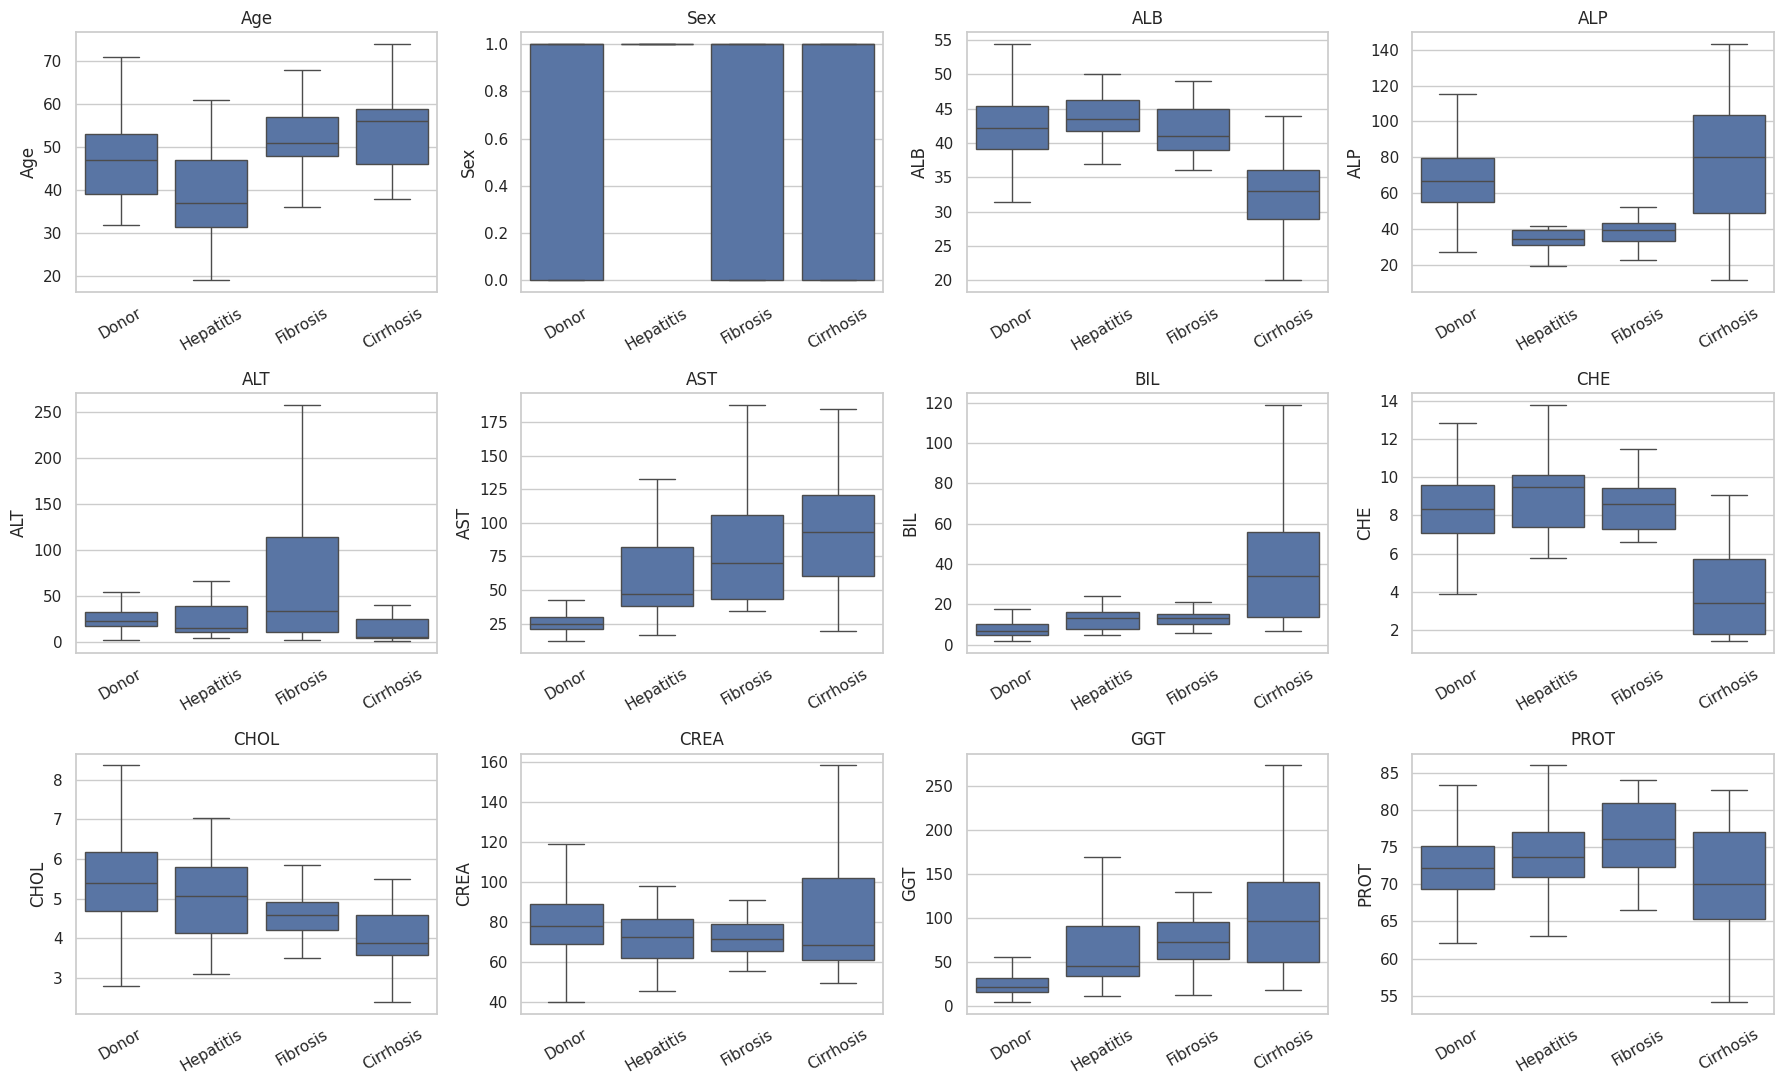

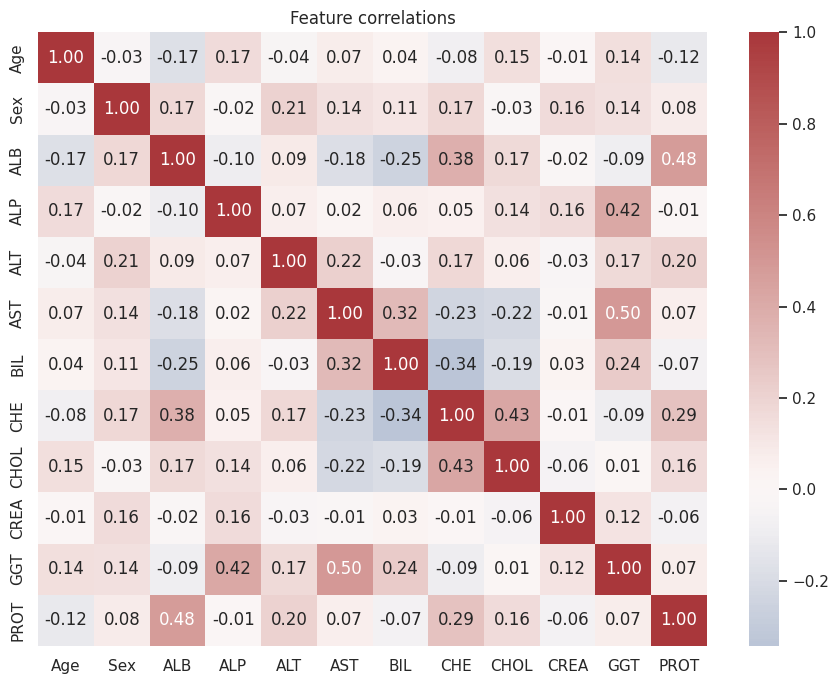

In [2]:
import matplotlib.pyplot as plt, seaborn as sns
sns.set_theme(style="whitegrid")
import os
os.makedirs("figures", exist_ok=True)

df = X_raw.copy().rename(columns={"CGT": "GGT"})
df["Sex"] = (df["Sex"].str.strip().str.lower() == "m").astype(int)   # 1 = male
cat = y_raw.iloc[:, 0].str.strip()
label_map = {"0=Blood Donor": "Donor", "0s=suspect Blood Donor": "Suspect",
             "1=Hepatitis": "Hepatitis", "2=Fibrosis": "Fibrosis", "3=Cirrhosis": "Cirrhosis"}
df["Category"] = cat.map(label_map)
assert df["Category"].notna().all() and len(df) == 615

# Decision: the 7 "suspect donors" are unconfirmed, so they are excluded from the primary
# 4-class task (Donor / Hepatitis / Fibrosis / Cirrhosis); 608 records remain.
df_main = df[df["Category"] != "Suspect"].reset_index(drop=True)
class_order = ["Donor", "Hepatitis", "Fibrosis", "Cirrhosis"]
print(df_main["Category"].value_counts()[class_order])

feats = ["Age","Sex","ALB","ALP","ALT","AST","BIL","CHE","CHOL","CREA","GGT","PROT"]
print(df_main.groupby("Category")[feats].median().loc[class_order].round(1).T)

fig, axes = plt.subplots(3, 4, figsize=(18, 11))
for ax, f in zip(axes.ravel(), feats):
    sns.boxplot(data=df_main, x="Category", y=f, order=class_order, ax=ax, showfliers=False)
    ax.set_xlabel(""); ax.set_title(f); ax.tick_params(axis="x", rotation=30)
plt.tight_layout(); plt.savefig("figures/eda_boxplots.png", dpi=120); plt.show()

plt.figure(figsize=(9, 7))
sns.heatmap(df_main[feats].corr(), annot=True, fmt=".2f", cmap="vlag", center=0)
plt.title("Feature correlations"); plt.tight_layout(); plt.savefig("figures/eda_corr.png", dpi=120); plt.show()

In [3]:
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import FunctionTransformer, StandardScaler, LabelEncoder
from sklearn.impute import SimpleImputer
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.model_selection import RepeatedStratifiedKFold, cross_validate
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import SMOTE

X = df_main[feats]
le = LabelEncoder().fit(class_order)           # fixed class order
y = le.transform(df_main["Category"])
print(dict(zip(le.classes_, range(4))))

skewed = ["ALP","ALT","AST","BIL","GGT"]
others = [f for f in feats if f not in skewed]
def make_prep():
    # log1p on skewed enzymes; median-impute + scale. All fitted inside each CV training fold.
    log_branch = Pipeline([("imp", SimpleImputer(strategy="median")),
                           ("log", FunctionTransformer(np.log1p)),
                           ("sc", StandardScaler())])
    oth_branch = Pipeline([("imp", SimpleImputer(strategy="median")), ("sc", StandardScaler())])
    return ColumnTransformer([("log", log_branch, skewed), ("oth", oth_branch, others)])

def build(clf, smote=False):
    steps = [("prep", make_prep())]
    if smote:
        steps.append(("smote", SMOTE(k_neighbors=4, random_state=SEED)))
        return ImbPipeline(steps + [("clf", clf)])
    return Pipeline(steps + [("clf", clf)])

models = {
 "Dummy (most frequent)": build(DummyClassifier(strategy="most_frequent")),
 "LogReg (balanced)":     build(LogisticRegression(max_iter=3000, class_weight="balanced", C=1.0)),
 "SVM-RBF (balanced)":    build(SVC(kernel="rbf", class_weight="balanced", C=3, probability=True, random_state=SEED)),
 "RandomForest (balanced)": build(RandomForestClassifier(n_estimators=400, class_weight="balanced_subsample", random_state=SEED, n_jobs=-1)),
 "HistGB (balanced)":     build(HistGradientBoostingClassifier(class_weight="balanced", max_depth=3, learning_rate=0.05, max_iter=200, random_state=SEED)),
 "LogReg + SMOTE":        build(LogisticRegression(max_iter=3000, C=1.0), smote=True),
 "RandomForest + SMOTE":  build(RandomForestClassifier(n_estimators=400, random_state=SEED, n_jobs=-1), smote=True),
}

cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=3, random_state=SEED)
scoring = {"accuracy":"accuracy","balanced_acc":"balanced_accuracy",
           "macro_precision":"precision_macro","macro_recall":"recall_macro","macro_f1":"f1_macro"}
rows = []
for name, m in models.items():
    r = cross_validate(m, X, y, cv=cv, scoring=scoring, n_jobs=-1)
    rows.append({"model": name, **{k: (r[f"test_{k}"].mean(), r[f"test_{k}"].std()) for k in scoring}})
    print("done", name)
res = pd.DataFrame(rows).set_index("model")
fmt = res.map(lambda t: f"{t[0]:.3f} ± {t[1]:.3f}")
print(fmt.to_string())
res_mean = res.map(lambda t: t[0])
res_mean.to_csv("figures/model_comparison_cv.csv")

{np.str_('Cirrhosis'): 0, np.str_('Donor'): 1, np.str_('Fibrosis'): 2, np.str_('Hepatitis'): 3}
done Dummy (most frequent)
done LogReg (balanced)
done SVM-RBF (balanced)
done RandomForest (balanced)
done HistGB (balanced)
done LogReg + SMOTE
done RandomForest + SMOTE
                              accuracy   balanced_acc macro_precision   macro_recall       macro_f1
model                                                                                              
Dummy (most frequent)    0.877 ± 0.000  0.250 ± 0.000   0.219 ± 0.000  0.250 ± 0.000  0.234 ± 0.000
LogReg (balanced)        0.906 ± 0.027  0.708 ± 0.068   0.641 ± 0.086  0.708 ± 0.068  0.654 ± 0.067
SVM-RBF (balanced)       0.944 ± 0.017  0.693 ± 0.094   0.735 ± 0.113  0.693 ± 0.094  0.699 ± 0.097
RandomForest (balanced)  0.933 ± 0.015  0.570 ± 0.088   0.775 ± 0.134  0.570 ± 0.088  0.620 ± 0.084
HistGB (balanced)        0.941 ± 0.018  0.651 ± 0.104   0.707 ± 0.102  0.651 ± 0.104  0.660 ± 0.097
LogReg + SMOTE           0.910 ±

In [4]:
from sklearn.model_selection import RandomizedSearchCV, StratifiedKFold
from scipy.stats import loguniform, randint

inner = StratifiedKFold(n_splits=3, shuffle=True, random_state=SEED)
outer = RepeatedStratifiedKFold(n_splits=5, n_repeats=2, random_state=SEED+1)

search_spaces = {
 "SVM-RBF (tuned)": (build(SVC(kernel="rbf", class_weight="balanced", probability=True, random_state=SEED)),
                     {"clf__C": loguniform(0.3, 100), "clf__gamma": loguniform(1e-3, 1)}),
 "LogReg (tuned)":  (build(LogisticRegression(max_iter=5000, class_weight="balanced")),
                     {"clf__C": loguniform(0.01, 100)}),
 "RF+SMOTE (tuned)": (build(RandomForestClassifier(n_estimators=300, random_state=SEED, n_jobs=-1), smote=True),
                     {"clf__max_depth": [3,5,8,None], "clf__min_samples_leaf": randint(1,6),
                      "clf__max_features": ["sqrt", 0.5]}),
}
nested_rows, best_models = [], {}
for name, (pipe, space) in search_spaces.items():
    rs = RandomizedSearchCV(pipe, space, n_iter=15, scoring="f1_macro", cv=inner,
                            random_state=SEED, n_jobs=-1, refit=True)
    r = cross_validate(rs, X, y, cv=outer, scoring=scoring, n_jobs=1)
    nested_rows.append({"model": name, **{k: (r[f"test_{k}"].mean(), r[f"test_{k}"].std()) for k in scoring}})
    rs.fit(X, y); best_models[name] = rs.best_estimator_
    print("done", name, rs.best_params_)
nested = pd.DataFrame(nested_rows).set_index("model")
print(nested.map(lambda t: f"{t[0]:.3f} ± {t[1]:.3f}").to_string())
nested.map(lambda t: t[0]).to_csv("figures/model_comparison_nested.csv")

done SVM-RBF (tuned) {'clf__C': np.float64(9.369391339777595), 'clf__gamma': np.float64(0.001378323745500718)}
done LogReg (tuned) {'clf__C': np.float64(0.012087541473056965)}
done RF+SMOTE (tuned) {'clf__max_depth': None, 'clf__max_features': 'sqrt', 'clf__min_samples_leaf': 3}
                       accuracy   balanced_acc macro_precision   macro_recall       macro_f1
model                                                                                       
SVM-RBF (tuned)   0.933 ± 0.020  0.766 ± 0.080   0.731 ± 0.107  0.766 ± 0.080  0.723 ± 0.078
LogReg (tuned)    0.921 ± 0.023  0.756 ± 0.066   0.678 ± 0.066  0.756 ± 0.066  0.695 ± 0.056
RF+SMOTE (tuned)  0.932 ± 0.026  0.689 ± 0.064   0.725 ± 0.119  0.689 ± 0.064  0.682 ± 0.083


Chosen model: SVM-RBF (tuned) 9.369391339777595 0.001378323745500718
              precision    recall  f1-score   support

   Cirrhosis      0.828     0.800     0.814        30
       Donor      0.981     0.994     0.988       533
    Fibrosis      0.550     0.524     0.537        21
   Hepatitis      0.632     0.500     0.558        24

    accuracy                          0.949       608
   macro avg      0.748     0.705     0.724       608
weighted avg      0.945     0.949     0.947       608



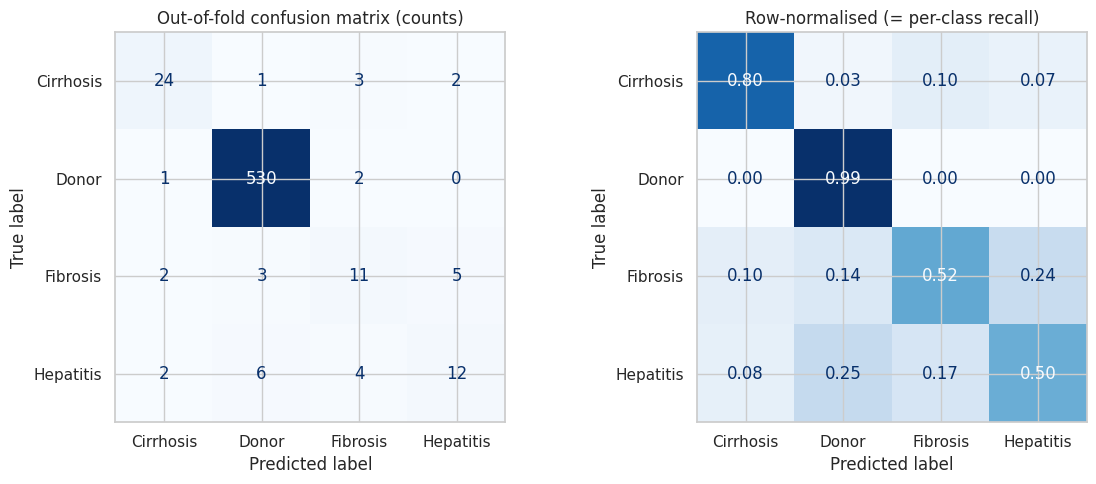


Binary screening: PR-AUC=0.961 (prevalence=0.123), ROC-AUC=0.986
 target_recall  threshold  recall  precision  flagged_%  missed_cases  false_alarms
          0.90      0.525   0.907      0.944       11.8             7             4
          0.95      0.174   0.960      0.791       15.0             3            19
          0.98      0.095   0.987      0.632       19.2             1            43


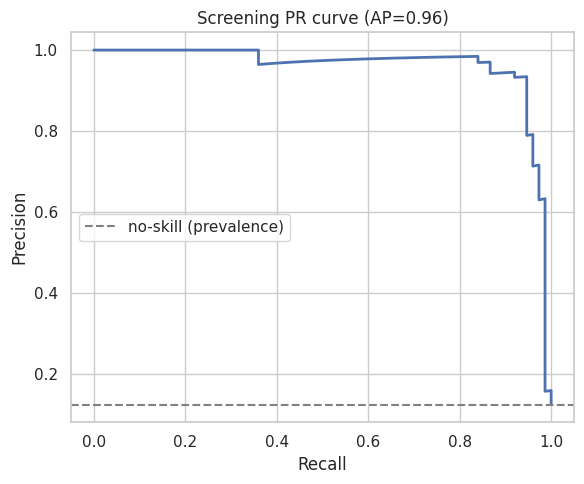

In [5]:
from sklearn.base import clone
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import (classification_report, confusion_matrix, ConfusionMatrixDisplay,
                             precision_recall_curve, average_precision_score, roc_auc_score)

best_name = "SVM-RBF (tuned)"
best = best_models[best_name]
print("Chosen model:", best_name, best.named_steps["clf"].get_params()["C"], best.named_steps["clf"].get_params()["gamma"])

skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
proba = cross_val_predict(clone(best), X, y, cv=skf, method="predict_proba", n_jobs=-1)
pred = proba.argmax(1)
names = list(le.classes_)
print(classification_report(y, pred, target_names=names, digits=3))

fig, ax = plt.subplots(1, 2, figsize=(12, 5))
ConfusionMatrixDisplay(confusion_matrix(y, pred), display_labels=names).plot(ax=ax[0], cmap="Blues", colorbar=False)
ax[0].set_title("Out-of-fold confusion matrix (counts)")
ConfusionMatrixDisplay(confusion_matrix(y, pred, normalize="true"), display_labels=names).plot(ax=ax[1], cmap="Blues", colorbar=False, values_format=".2f")
ax[1].set_title("Row-normalised (= per-class recall)")
plt.tight_layout(); plt.savefig("figures/confusion_matrix.png", dpi=120); plt.show()

# ---- Screening view: Donor (negative) vs any liver-disease stage (positive) ----
donor_idx = list(le.classes_).index("Donor")
y_bin = (y != donor_idx).astype(int)
score = 1 - proba[:, donor_idx]                       # P(any disease)
ap = average_precision_score(y_bin, score); auc = roc_auc_score(y_bin, score)
print(f"\nBinary screening: PR-AUC={ap:.3f} (prevalence={y_bin.mean():.3f}), ROC-AUC={auc:.3f}")

prec, rec, thr = precision_recall_curve(y_bin, score)
rows = []
for target in [0.90, 0.95, 0.98]:
    ok = np.where(rec[:-1] >= target)[0]; i = ok[-1]          # highest threshold that keeps recall >= target
    t = thr[i]; flag = score >= t
    rows.append({"target_recall": target, "threshold": round(t, 3), "recall": round(rec[i], 3),
                 "precision": round(prec[i], 3), "flagged_%": round(100*flag.mean(), 1),
                 "missed_cases": int(((~flag) & (y_bin == 1)).sum()), "false_alarms": int((flag & (y_bin == 0)).sum())})
screen = pd.DataFrame(rows); print(screen.to_string(index=False))
screen.to_csv("figures/screening_thresholds.csv", index=False)

plt.figure(figsize=(6, 5))
plt.plot(rec, prec, lw=2); plt.axhline(y_bin.mean(), ls="--", c="gray", label="no-skill (prevalence)")
plt.xlabel("Recall"); plt.ylabel("Precision"); plt.title(f"Screening PR curve (AP={ap:.2f})"); plt.legend()
plt.tight_layout(); plt.savefig("figures/pr_curve.png", dpi=120); plt.show()

feature   mean    std
    Age 0.1433 0.0466
    AST 0.1360 0.0382
    GGT 0.0768 0.0495
    ALP 0.0639 0.0332
    BIL 0.0609 0.0533
    ALT 0.0561 0.0630
    CHE 0.0518 0.0592
   CHOL 0.0335 0.0283
   PROT 0.0293 0.0255
    Sex 0.0222 0.0236
    ALB 0.0165 0.0357
   CREA 0.0075 0.0199


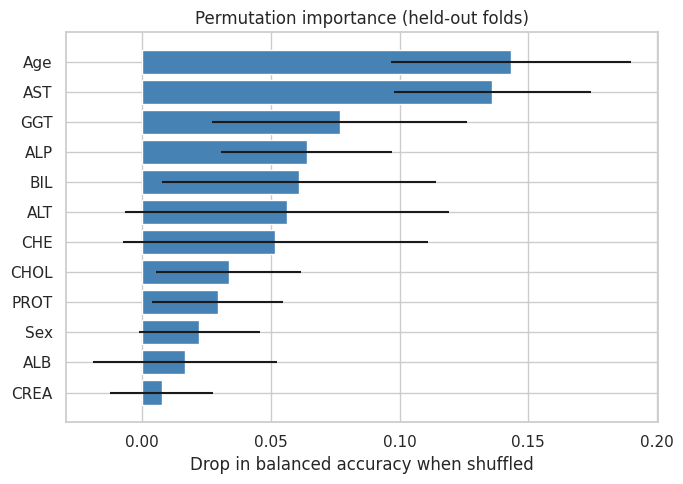

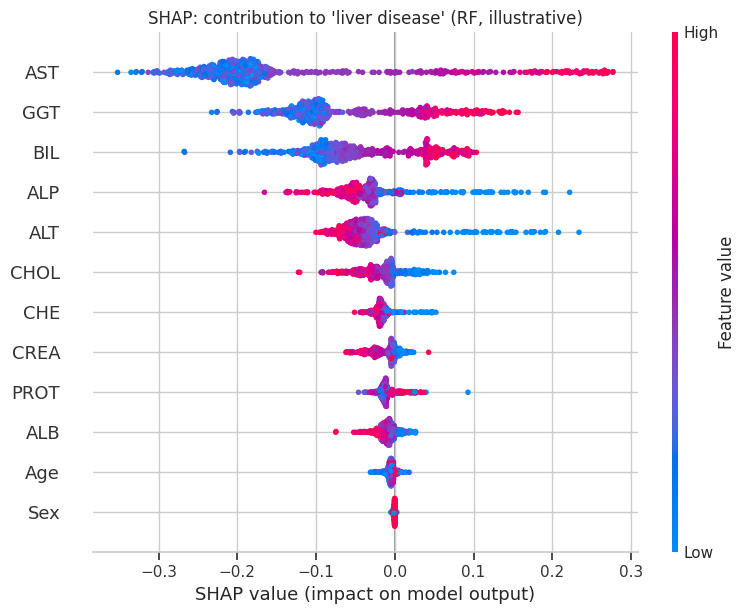

AST     0.190
GGT     0.092
BIL     0.072
ALP     0.050
ALT     0.050
CHOL    0.025
CHE     0.019
CREA    0.014


In [6]:
from sklearn.inspection import permutation_importance
import shap

# 1) Permutation importance of the chosen SVM pipeline, measured on held-out folds (balanced accuracy)
imps = []
for tr, te in skf.split(X, y):
    m = clone(best).fit(X.iloc[tr], y[tr])
    r = permutation_importance(m, X.iloc[te], y[te], scoring="balanced_accuracy",
                               n_repeats=20, random_state=SEED, n_jobs=-1)
    imps.append(r.importances_mean)
imp = pd.DataFrame({"feature": feats, "mean": np.mean(imps, 0), "std": np.std(imps, 0)}).sort_values("mean")
print(imp.sort_values("mean", ascending=False).round(4).to_string(index=False))
plt.figure(figsize=(7, 5))
plt.barh(imp["feature"], imp["mean"], xerr=imp["std"], color="steelblue")
plt.xlabel("Drop in balanced accuracy when shuffled"); plt.title("Permutation importance (held-out folds)")
plt.tight_layout(); plt.savefig("figures/permutation_importance.png", dpi=120); plt.show()

# 2) SHAP on a binary "any liver disease vs donor" random forest (TreeExplainer) for direction of effects
Xt = pd.DataFrame(make_prep().fit_transform(X), columns=skewed + others)
rf_bin = RandomForestClassifier(n_estimators=400, class_weight="balanced_subsample", min_samples_leaf=2,
                                random_state=SEED, n_jobs=-1).fit(Xt, y_bin)
sv = shap.TreeExplainer(rf_bin).shap_values(Xt)
sv = sv[1] if isinstance(sv, list) else (sv[..., 1] if sv.ndim == 3 else sv)
shap.summary_plot(sv, Xt, show=False, max_display=12)
plt.title("SHAP: contribution to 'liver disease' (RF, illustrative)")
plt.tight_layout(); plt.savefig("figures/shap_summary.png", dpi=120, bbox_inches="tight"); plt.show()
shap_rank = pd.Series(np.abs(sv).mean(0), index=Xt.columns).sort_values(ascending=False)
print(shap_rank.round(3).head(8).to_string())

In [7]:
import joblib, json, shutil

# ---- Error analysis ----
cm = pd.crosstab(pd.Series(le.inverse_transform(y), name="true"), pd.Series(le.inverse_transform(pred), name="predicted"))
errs = [(t, p, int(cm.loc[t, p])) for t in cm.index for p in cm.columns if t != p and cm.loc[t, p] > 0]
print("Misclassification pairs (true -> predicted : count)")
for t, p, n in sorted(errs, key=lambda e: -e[2]): print(f"  {t:10s} -> {p:10s}: {n}")
stage_confusion = sum(n for t, p, n in errs if t != "Donor" and p != "Donor")
print(f"\nStage-vs-stage confusions (both non-donor): {stage_confusion} of {len(errs) and sum(n for *_, n in errs)} errors")
bad = df_main.assign(true=le.inverse_transform(y), pred=le.inverse_transform(pred))
print("\nMissed disease cases (predicted Donor):")
print(bad[(bad.true != "Donor") & (bad.pred == "Donor")][["true"] + ["Age","AST","GGT","BIL","ALB"]].round(1).to_string())

# ---- Final model on all data + demo ----
THRESH = float(screen.loc[screen.target_recall == 0.95, "threshold"].iloc[0])   # ~95% recall operating point
final = clone(best).fit(X, y)
joblib.dump({"model": final, "classes": names, "features": feats, "screen_threshold": THRESH}, "hcv_screening_model.joblib")

def screen_donor(Age, Sex, ALB, ALP, ALT, AST, BIL, CHE, CHOL, CREA, GGT, PROT):
    """Sex: 'm' or 'f'. Returns predicted class, P(any liver disease) and a follow-up flag."""
    row = pd.DataFrame([dict(Age=Age, Sex=int(str(Sex).lower() == "m"), ALB=ALB, ALP=ALP, ALT=ALT, AST=AST,
                             BIL=BIL, CHE=CHE, CHOL=CHOL, CREA=CREA, GGT=GGT, PROT=PROT)])[feats]
    p = final.predict_proba(row)[0]
    risk = 1 - p[names.index("Donor")]
    return {"predicted_class": names[int(p.argmax())], "P(any_liver_disease)": round(float(risk), 3),
            "recommend_confirmatory_test": bool(risk >= THRESH),
            "class_probabilities": {n: round(float(v), 3) for n, v in zip(names, p)}}

ex_disease = df_main[df_main.Category == "Cirrhosis"].iloc[0]; ex_donor = df_main[df_main.Category == "Donor"].iloc[0]
for lab, r in [("Cirrhosis example", ex_disease), ("Donor example", ex_donor)]:
    print(lab, "->", screen_donor(**{k: r[k] if k != "Sex" else ("m" if r[k] == 1 else "f") for k in feats}))
shutil.make_archive("hcv_results", "zip", "figures"); print("saved: hcv_screening_model.joblib, hcv_results.zip, threshold =", round(THRESH, 3))

Misclassification pairs (true -> predicted : count)
  Hepatitis  -> Donor     : 6
  Fibrosis   -> Hepatitis : 5
  Hepatitis  -> Fibrosis  : 4
  Cirrhosis  -> Fibrosis  : 3
  Fibrosis   -> Donor     : 3
  Cirrhosis  -> Hepatitis : 2
  Donor      -> Fibrosis  : 2
  Fibrosis   -> Cirrhosis : 2
  Hepatitis  -> Cirrhosis : 2
  Cirrhosis  -> Donor     : 1
  Donor      -> Cirrhosis : 1

Stage-vs-stage confusions (both non-donor): 18 of 31 errors

Missed disease cases (predicted Donor):
          true  Age   AST   GGT   BIL   ALB
533  Hepatitis   38  33.1  18.9   7.0  45.0
534  Hepatitis   19  67.0  65.0  12.0  41.0
538  Hepatitis   29  39.0  37.0  15.0  49.0
539  Hepatitis   30  45.0  43.0  14.0  45.0
547  Hepatitis   44  31.1  27.6  13.0  49.0
553  Hepatitis   33  16.7  11.5   6.0  43.0
572   Fibrosis   57  35.8  27.9  18.0  43.0
574   Fibrosis   49  39.0  53.0   9.0  39.0
576   Fibrosis   56  34.0  84.0  10.0  39.0
607  Cirrhosis   59  80.0  34.0  12.0  36.0
Cirrhosis example -> {'predicted

## Results and conclusions

**Model comparison (repeated 5-fold CV, macro metrics)**: the always-"Donor" baseline reaches 87.7% accuracy but only 0.25 balanced accuracy. After nested-CV tuning, the **class-weighted RBF-SVM** was best (balanced accuracy / macro-recall 0.77, macro-F1 0.72), ahead of tuned logistic regression (0.76 / 0.70) and RF+SMOTE (0.69 / 0.68). SMOTE did not beat class weighting.

**Chosen model, out-of-fold, 4 classes:** accuracy 0.949; Donor recall 0.994 / precision 0.981; Cirrhosis 0.80 / 0.83; Hepatitis 0.50 / 0.63; Fibrosis 0.52 / 0.55.

**Screening view (donor vs any disease):** PR-AUC 0.961 (prevalence 0.123), ROC-AUC 0.986.

| Operating point | Recall | Precision | Missed | False alarms |
|---|---|---|---|---|
| threshold 0.525 | 0.91 | 0.94 | 7 | 4 |
| **threshold 0.174 (used in demo)** | **0.96** | **0.79** | 3 | 19 |
| threshold 0.095 | 0.99 | 0.63 | 1 | 43 |

For a donor-screening setting, where a missed case costs more than an extra confirmatory test, the 0.174 operating point is the natural choice.

**What drives predictions:** AST, GGT and bilirubin (permutation importance and SHAP agree), which matches the clinical picture. Age also ranks high. This is probably a dataset artefact (donor and patient age distributions differ), so treat it with caution.

**Errors:** 18 of the 31 errors are confusions between disease stages (hepatitis, fibrosis, cirrhosis). Distinguishing stages is the hard part and screening is the easy part. The 10 missed cases (mostly mild hepatitis) have near-normal panels.

**Limitations:** only 75 positive records, so per-class numbers are noisy (see the ± values). The donors are German, so transfer to Indian populations is unverified. Liver enzymes indicate liver injury, not HCV infection itself. Hyperparameters were chosen on the full data before the out-of-fold evaluation, so those numbers are slightly optimistic. The nested-CV numbers are the unbiased estimate.